<a href="https://colab.research.google.com/github/MatthewSilitonga99/ai-career-advisor/blob/main/Tugas05_TransferLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 05 — Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas
Dataset : Oxford-IIIT Pet, subset 10 kelas (5 ras kucing + 5 ras anjing), ~2.000 citra
Split   : stratified 70% train / 15% validation / 15% test
Arsitektur utama : ResNet-18 (ImageNet1K_V1)
Kondisi : B1 (from scratch), B2 (feature extraction), B3 (progressive fine-tuning),
          B4 (uji kontrol augmentasi), B5 (arsitektur pembanding, bonus)
Jalankan di Google Colab dengan runtime GPU T4, lalu pilih Runtime > Run all.

In [16]:
import os
import json # Tadi lupa
import time
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = "./data"
OUT = Path("outputs")
(OUT / "metrics").mkdir(parents=True, exist_ok=True)
(OUT / "figures").mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 32
MAX_EPOCHS = 30          # batas atas; early stopping biasanya menghentikan lebih awal
PATIENCE = 5             # early stopping pada validation loss (rentang 3-5 sesuai spesifikasi)
LR_HEAD = 1e-3           # learning rate classifier head
LR_BACKBONE = 1e-4       # learning rate blok backbone yang di-unfreeze (B3)
WEIGHT_DECAY = 1e-2
NUM_CLASSES = 10

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


def set_seed(seed=SEED):
    """Seed tetap untuk Python, NumPy, dan PyTorch agar hasil dapat direproduksi."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)


set_seed()

Device: cuda
GPU: Tesla T4


## 1. Dataset: subset 10 kelas dan pembagian stratified 70/15/15

In [2]:
ARCHS = {
    "resnet18": (models.resnet18, models.ResNet18_Weights.IMAGENET1K_V1),
    "efficientnet_b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "mobilenet_v3_small": (models.mobilenet_v3_small, models.MobileNet_V3_Small_Weights.IMAGENET1K_V1),
}

# Normalisasi standar ImageNet (mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

raw_trainval = datasets.OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category", download=True)
raw_test = datasets.OxfordIIITPet(DATA_ROOT, split="test", target_types="category", download=True)
ALL_CLASSES = raw_trainval.classes

# Konvensi Oxford-IIIT Pet: ras kucing diawali huruf kapital, ras anjing huruf kecil.
CATS = sorted([c for c in ALL_CLASSES if c[0].isupper()])[:5]
DOGS = sorted([c for c in ALL_CLASSES if c[0].islower()])[:5]
SELECTED = CATS + DOGS
NAME_TO_NEW = {c: i for i, c in enumerate(SELECTED)}
print("Kelas terpilih:")
for i, c in enumerate(SELECTED):
    print(f"  {i}: {c}")


def collect(ds):
    items = []
    for img, lbl in ds:
        cname = ALL_CLASSES[lbl]
        if cname in NAME_TO_NEW:
            items.append((img.convert("RGB"), NAME_TO_NEW[cname]))
    return items


pool = collect(raw_trainval) + collect(raw_test)
IMAGES = [p[0] for p in pool]
LABELS = np.array([p[1] for p in pool])
print("Total citra terpilih:", len(pool))

idx_all = np.arange(len(pool))
idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=LABELS, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=LABELS[idx_tmp], random_state=SEED)
SPLITS = {"train": idx_train, "val": idx_val, "test": idx_test}
for k, v in SPLITS.items():
    print(f"{k:>5}: {len(v)} citra, distribusi kelas = {np.bincount(LABELS[v], minlength=NUM_CLASSES).tolist()}")

100%|██████████| 792M/792M [00:36<00:00, 21.8MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.35MB/s]


Kelas terpilih:
  0: Abyssinian
  1: American Bulldog
  2: American Pit Bull Terrier
  3: Basset Hound
  4: Beagle
Total citra terpilih: 998
train: 698 citra, distribusi kelas = [138, 140, 140, 140, 140, 0, 0, 0, 0, 0]
  val: 150 citra, distribusi kelas = [30, 30, 30, 30, 30, 0, 0, 0, 0, 0]
 test: 150 citra, distribusi kelas = [30, 30, 30, 30, 30, 0, 0, 0, 0, 0]


## 2. Pipeline transformasi
Data latih dengan augmentasi aktif untuk B1-B3, data validasi/uji hanya deterministik.

In [3]:
TF_EVAL = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

TF_TRAIN_NOAUG = TF_EVAL  # B4 skenario 1: hanya Resize/Crop dan Normalisasi

TF_TRAIN_AUG = transforms.Compose([  # B4 skenario 2 dan default B1-B3
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


class PetSubset(Dataset):
    def __init__(self, images, labels, indices, transform):
        self.images = images
        self.labels = labels
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        return self.transform(self.images[j]), int(self.labels[j])


def make_loaders(train_tf):
    g = torch.Generator()
    g.manual_seed(SEED)
    train_loader = DataLoader(
        PetSubset(IMAGES, LABELS, SPLITS["train"], train_tf),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
        worker_init_fn=seed_worker, generator=g,
    )
    # Train set dengan transformasi deterministik, dipakai untuk mengukur akurasi latih
    # yang adil (tanpa augmentasi) saat menghitung celah generalisasi.
    train_eval_loader = DataLoader(
        PetSubset(IMAGES, LABELS, SPLITS["train"], TF_EVAL),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    )
    val_loader = DataLoader(
        PetSubset(IMAGES, LABELS, SPLITS["val"], TF_EVAL),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    )
    test_loader = DataLoader(
        PetSubset(IMAGES, LABELS, SPLITS["test"], TF_EVAL),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
    )
    return train_loader, train_eval_loader, val_loader, test_loader

## 3. Konstruksi model untuk setiap kondisi
- B1: from scratch (weights=None), seluruh parameter dilatih.
- B2: feature extraction, backbone dibekukan, hanya head baru yang dilatih.
- B3: progressive fine-tuning, layer4 dibuka dengan lr lebih kecil dari head.

In [4]:
def build_model(condition, arch="resnet18"):
    """Mengembalikan (model, param_groups, trainable_params, total_params)."""
    pretrained = condition != "B1"
    ctor, weights = ARCHS[arch]
    model = ctor(weights=weights if pretrained else None)

    # Bekukan seluruh backbone sebelum head diganti (head baru selalu trainable).
    if condition != "B1":
        for p in model.parameters():
            p.requires_grad = False

    # Ganti classifier head untuk 10 kelas.
    if arch == "resnet18":
        last_block = model.layer4
        in_f = model.fc.in_features           # 512
        model.fc = nn.Linear(in_f, NUM_CLASSES)
        head = model.fc
    elif arch == "efficientnet_b0":
        last_block = model.features[-1]
        in_f = model.classifier[1].in_features  # 1280
        model.classifier[1] = nn.Linear(in_f, NUM_CLASSES)
        head = model.classifier[1]
    elif arch == "mobilenet_v3_small":
        last_block = model.features[-1]
        in_f = model.classifier[3].in_features  # 1024
        model.classifier[3] = nn.Linear(in_f, NUM_CLASSES)
        head = model.classifier[3]
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")

    if condition == "B1":
        groups = [{"params": list(model.parameters()), "lr": LR_HEAD}]
    elif condition == "B2":
        groups = [{"params": list(head.parameters()), "lr": LR_HEAD}]
    elif condition == "B3":
        for p in last_block.parameters():
            p.requires_grad = True
        groups = [
            {"params": list(last_block.parameters()), "lr": LR_BACKBONE},
            {"params": list(head.parameters()), "lr": LR_HEAD},
        ]
    else:
        raise ValueError(f"Kondisi tidak dikenal: {condition}")

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return model, groups, trainable, total


# Verifikasi jumlah parameter (ResNet-18, B2 harus 5.130 = 512*10 + 10)
_m, _, tr, tot = build_model("B2", "resnet18")
print(f"Verifikasi B2 ResNet-18 -> trainable: {tr:,} / total: {tot:,}")
assert tr == 512 * NUM_CLASSES + NUM_CLASSES, "Jumlah trainable parameter B2 tidak sesuai"
del _m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 172MB/s]


Verifikasi B2 ResNet-18 -> trainable: 5,130 / total: 11,181,642


## 4. Fungsi training dengan early stopping dan pencatatan metrik

In [5]:
def freeze_frozen_bn(model):
    """BatchNorm pada blok yang dibekukan tetap berada dalam mode eval.
    Tanpa ini, statistik running mean/var pada backbone beku tetap ikut berubah."""
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in mod.parameters(recurse=False)):
                mod.eval()


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, n = 0.0, 0
    probs_all, ys_all = [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        n += x.size(0)
        probs_all.append(torch.softmax(out, dim=1).cpu())
        ys_all.append(y.cpu())
    probs = torch.cat(probs_all).numpy()
    ys = torch.cat(ys_all).numpy()
    preds = probs.argmax(axis=1)
    acc = float((preds == ys).mean())
    return total_loss / n, acc, preds, ys, probs


def train_one_condition(condition, aug=True, arch="resnet18", tag=None):
    tag = tag or f"{condition}_{arch}_{'aug' if aug else 'noaug'}"
    set_seed()  # seed di-reset per eksperimen agar inisialisasi & urutan batch konsisten
    train_tf = TF_TRAIN_AUG if aug else TF_TRAIN_NOAUG
    train_loader, train_eval_loader, val_loader, test_loader = make_loaders(train_tf)

    model, groups, trainable, total = build_model(condition, arch)
    model.to(DEVICE)
    lr_per_group = [g["lr"] for g in groups]
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    print(f"\n=== {tag} | trainable {trainable:,}/{total:,} | lr per grup {lr_per_group} ===")
    history = []
    best_val_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t0 = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        freeze_frozen_bn(model)
        running, seen = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item() * x.size(0)
            seen += x.size(0)
        train_loss_aug = running / seen

        train_loss, train_acc, *_ = evaluate(model, train_eval_loader, criterion)
        val_loss, val_acc, *_ = evaluate(model, val_loader, criterion)

        history.append({
            "epoch": epoch,
            "train_loss_aug": train_loss_aug,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
        })
        print(f"  epoch {epoch:02d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | "
              f"train_acc {train_acc:.4f} | val_acc {val_acc:.4f}")

        if val_loss < best_val_loss - 1e-4:
            best_val_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"  Early stopping pada epoch {epoch} (patience={PATIENCE})")
                break

    train_time = time.time() - t0
    model.load_state_dict(best_state)
    criterion_eval = nn.CrossEntropyLoss()
    _, test_acc, test_preds, test_ys, test_probs = evaluate(model, test_loader, criterion_eval)
    test_macro_f1 = float(f1_score(test_ys, test_preds, average="macro"))

    best_row = history[best_epoch - 1]
    res = {
        "tag": tag,
        "condition": condition,
        "arch": arch,
        "aug": aug,
        "trainable_params": trainable,
        "total_params": total,
        "lr_per_group": lr_per_group,
        "epochs_run": len(history),
        "best_epoch": best_epoch,
        "train_acc_best": best_row["train_acc"],
        "val_acc_best": best_row["val_acc"],
        "val_loss_best": best_row["val_loss"],
        "gap_train_val_acc": best_row["train_acc"] - best_row["val_acc"],
        "test_acc": test_acc,
        "test_macro_f1": test_macro_f1,
        "train_time_sec": round(train_time, 2),
        "seed": SEED,
        "history": history,
        "model": model,
        "preds": test_preds,
        "ys": test_ys,
        "probs": test_probs,
    }
    save_run(res)
    print(f"  -> test_acc {test_acc:.4f} | test_macro_f1 {test_macro_f1:.4f} | best_epoch {best_epoch} | "
          f"waktu {train_time:.1f}s")
    return res


def save_run(res):
    pd.DataFrame(res["history"]).to_csv(OUT / "metrics" / f"history_{res['tag']}.csv", index=False)
    meta = {k: v for k, v in res.items() if k not in ("history", "model", "preds", "ys", "probs")}
    with open(OUT / "metrics" / f"metrics_{res['tag']}.json", "w") as f:
        json.dump(meta, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

## 5. Eksekusi kondisi B1, B2, B3 (augmentasi aktif)

In [6]:
RESULTS = {}
for cond in ["B1", "B2", "B3"]:
    RESULTS[cond] = train_one_condition(cond, aug=True, tag=cond)


=== B1 | trainable 11,181,642/11,181,642 | lr per grup [0.001] ===
  epoch 01 | train_loss 5.8763 | val_loss 5.0979 | train_acc 0.3066 | val_acc 0.2733
  epoch 02 | train_loss 1.6208 | val_loss 1.6847 | train_acc 0.3166 | val_acc 0.2800
  epoch 03 | train_loss 1.5472 | val_loss 1.6605 | train_acc 0.3424 | val_acc 0.3000
  epoch 04 | train_loss 1.3890 | val_loss 1.5607 | train_acc 0.3968 | val_acc 0.3600
  epoch 05 | train_loss 1.7553 | val_loss 1.7758 | train_acc 0.2335 | val_acc 0.2467
  epoch 06 | train_loss 1.7784 | val_loss 1.8941 | train_acc 0.2937 | val_acc 0.2667
  epoch 07 | train_loss 1.4903 | val_loss 1.6423 | train_acc 0.4169 | val_acc 0.4067
  epoch 08 | train_loss 1.4415 | val_loss 1.5667 | train_acc 0.3481 | val_acc 0.3200
  epoch 09 | train_loss 1.3455 | val_loss 1.5274 | train_acc 0.4341 | val_acc 0.3333
  epoch 10 | train_loss 1.1098 | val_loss 1.3943 | train_acc 0.5487 | val_acc 0.4467
  epoch 11 | train_loss 1.2892 | val_loss 1.5230 | train_acc 0.4413 | val_acc 0.34

## 6. Kondisi B4: uji kontrol augmentasi
Basis B4 (B2 atau B3) dipilih otomatis berdasarkan validation accuracy, bukan test set,
agar tidak terjadi kebocoran data pada pemilihan konfigurasi.

In [7]:
BASE_B4 = max(["B2", "B3"], key=lambda c: RESULTS[c]["val_acc_best"])
print(f"Basis B4 (val acc tertinggi): {BASE_B4}")
RESULTS["B4_noaug"] = train_one_condition(BASE_B4, aug=False, tag=f"B4_{BASE_B4}_noaug")
# Pasangan B4: RESULTS[BASE_B4] (dengan augmentasi) vs RESULTS["B4_noaug"] (tanpa augmentasi)

Basis B4 (val acc tertinggi): B2

=== B4_B2_noaug | trainable 5,130/11,181,642 | lr per grup [0.001] ===
  epoch 01 | train_loss 0.6341 | val_loss 0.6591 | train_acc 0.8266 | val_acc 0.8200
  epoch 02 | train_loss 0.3479 | val_loss 0.3964 | train_acc 0.9312 | val_acc 0.8867
  epoch 03 | train_loss 0.2608 | val_loss 0.3216 | train_acc 0.9413 | val_acc 0.9133
  epoch 04 | train_loss 0.2147 | val_loss 0.2906 | train_acc 0.9570 | val_acc 0.9133
  epoch 05 | train_loss 0.1886 | val_loss 0.2673 | train_acc 0.9570 | val_acc 0.9400
  epoch 06 | train_loss 0.1766 | val_loss 0.2579 | train_acc 0.9542 | val_acc 0.9200
  epoch 07 | train_loss 0.1536 | val_loss 0.2375 | train_acc 0.9585 | val_acc 0.9467
  epoch 08 | train_loss 0.1411 | val_loss 0.2279 | train_acc 0.9613 | val_acc 0.9400
  epoch 09 | train_loss 0.1238 | val_loss 0.2275 | train_acc 0.9742 | val_acc 0.9333
  epoch 10 | train_loss 0.1165 | val_loss 0.2256 | train_acc 0.9742 | val_acc 0.9333
  epoch 11 | train_loss 0.1128 | val_loss 0.2

## 7. Kondisi B5: arsitektur pembanding (bonus)
Konfigurasi terbaik (BASE_B4) dijalankan pada EfficientNet-B0 dan MobileNetV3-Small.

In [8]:
for arch in ["efficientnet_b0", "mobilenet_v3_small"]:
    tag = f"B5_{arch}"
    RESULTS[tag] = train_one_condition(BASE_B4, aug=True, arch=arch, tag=tag)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 82.7MB/s]



=== B5_efficientnet_b0 | trainable 12,810/4,020,358 | lr per grup [0.001] ===
  epoch 01 | train_loss 0.4762 | val_loss 0.5169 | train_acc 0.9470 | val_acc 0.9267
  epoch 02 | train_loss 0.2417 | val_loss 0.2835 | train_acc 0.9585 | val_acc 0.9400
  epoch 03 | train_loss 0.1797 | val_loss 0.2285 | train_acc 0.9685 | val_acc 0.9467
  epoch 04 | train_loss 0.1521 | val_loss 0.2013 | train_acc 0.9728 | val_acc 0.9467
  epoch 05 | train_loss 0.1295 | val_loss 0.1827 | train_acc 0.9756 | val_acc 0.9467
  epoch 06 | train_loss 0.1149 | val_loss 0.1725 | train_acc 0.9828 | val_acc 0.9533
  epoch 07 | train_loss 0.1059 | val_loss 0.1682 | train_acc 0.9828 | val_acc 0.9533
  epoch 08 | train_loss 0.0981 | val_loss 0.1576 | train_acc 0.9842 | val_acc 0.9467
  epoch 09 | train_loss 0.0911 | val_loss 0.1549 | train_acc 0.9842 | val_acc 0.9533
  epoch 10 | train_loss 0.0844 | val_loss 0.1481 | train_acc 0.9857 | val_acc 0.9533
  epoch 11 | train_loss 0.0794 | val_loss 0.1438 | train_acc 0.9842 | v

100%|██████████| 9.83M/9.83M [00:00<00:00, 120MB/s]


=== B5_mobilenet_v3_small | trainable 10,250/1,528,106 | lr per grup [0.001] ===


  epoch 01 | train_loss 0.4612 | val_loss 0.5198 | train_acc 0.8768 | val_acc 0.8733
  epoch 02 | train_loss 0.2816 | val_loss 0.3569 | train_acc 0.9269 | val_acc 0.8867
  epoch 03 | train_loss 0.2228 | val_loss 0.3149 | train_acc 0.9398 | val_acc 0.9000
  epoch 04 | train_loss 0.1890 | val_loss 0.2952 | train_acc 0.9527 | val_acc 0.9067
  epoch 05 | train_loss 0.1647 | val_loss 0.2790 | train_acc 0.9585 | val_acc 0.9200
  epoch 06 | train_loss 0.1482 | val_loss 0.2683 | train_acc 0.9656 | val_acc 0.9000
  epoch 07 | train_loss 0.1326 | val_loss 0.2719 | train_acc 0.9685 | val_acc 0.9200
  epoch 08 | train_loss 0.1273 | val_loss 0.2690 | train_acc 0.9642 | val_acc 0.9133
  epoch 09 | train_loss 0.1158 | val_loss 0.2606 | train_acc 0.9699 | val_acc 0.9200
  epoch 10 | train_loss 0.1053 | val_loss 0.2552 | train_acc 0.9713 | val_acc 0.9200
  epoch 11 | train_loss 0.0978 | val_loss 0.2522 | train_acc 0.9742 | val_acc 0.9200
  epoch 12 | train_loss 0.0916 | val_loss 0.2502 | train_acc 0.97

## 8. Tabel konsolidasi (C1) dan kurva loss

              kondisi         arsitektur  augmentasi  trainable_params  total_params     lr_per_grup  epochs_run  best_epoch  train_acc_best  val_acc_best  gap_train_val  test_acc  test_macro_f1  train_time_sec
                   B1           resnet18        True          11181642      11181642         [0.001]          15          10          0.5487        0.4467         0.1020    0.5000         0.4859          136.11
                   B2           resnet18        True              5130      11181642         [0.001]          29          24          0.9599        0.9533         0.0066    0.9067         0.9060          232.87
                   B3           resnet18        True           8398858      11181642 [0.0001, 0.001]           9           4          0.9914        0.9200         0.0714    0.9333         0.9334           71.59
             B4_noaug           resnet18       False              5130      11181642         [0.001]          30          28          0.9971        0.9400  

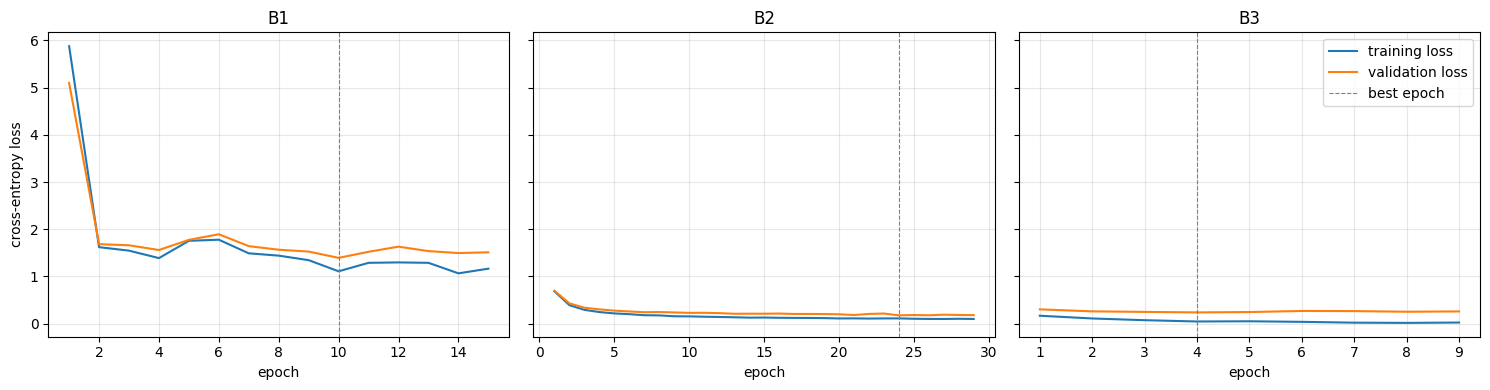

In [9]:
rows = []
for tag, r in RESULTS.items():
    rows.append({
        "kondisi": tag,
        "arsitektur": r["arch"],
        "augmentasi": r["aug"],
        "trainable_params": r["trainable_params"],
        "total_params": r["total_params"],
        "lr_per_grup": str(r["lr_per_group"]),
        "epochs_run": r["epochs_run"],
        "best_epoch": r["best_epoch"],
        "train_acc_best": round(r["train_acc_best"], 4),
        "val_acc_best": round(r["val_acc_best"], 4),
        "gap_train_val": round(r["gap_train_val_acc"], 4),
        "test_acc": round(r["test_acc"], 4),
        "test_macro_f1": round(r["test_macro_f1"], 4),
        "train_time_sec": r["train_time_sec"],
    })
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "metrics" / "summary.csv", index=False)
with open(OUT / "metrics" / "all_metrics.json", "w") as f:
    json.dump(rows, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
display_df = summary
print(display_df.to_string(index=False))


def plot_loss_curves(tags, path):
    fig, axes = plt.subplots(1, len(tags), figsize=(5 * len(tags), 4), sharey=True)
    if len(tags) == 1:
        axes = [axes]
    for ax, tag in zip(axes, tags):
        h = pd.DataFrame(RESULTS[tag]["history"])
        ax.plot(h["epoch"], h["train_loss"], label="training loss")
        ax.plot(h["epoch"], h["val_loss"], label="validation loss")
        ax.axvline(RESULTS[tag]["best_epoch"], ls="--", c="gray", lw=0.8, label="best epoch")
        ax.set_title(tag)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("cross-entropy loss")
    axes[-1].legend()
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()


plot_loss_curves(["B1", "B2", "B3"], OUT / "figures" / "loss_curves_B1_B2_B3.png")

## 9. Confusion matrix model terbaik (validasi tertinggi di B1-B3)

In [11]:


ARCHS = {
    "resnet18": (models.resnet18, models.ResNet18_Weights.IMAGENET1K_V1),
    "efficientnet_b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "mobilenet_v3_small": (models.mobilenet_v3_small, models.MobileNet_V3_Small_Weights.IMAGENET1K_V1),
}

# Normalisasi standar ImageNet
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# 12 ras kucing dalam Oxford-IIIT Pet. Sisanya adalah ras anjing.
CAT_BREEDS = {
    "Abyssinian", "Bengal", "Birman", "Bombay", "British_Shorthair", "Egyptian_Mau",
    "Maine_Coon", "Persian", "Ragdoll", "Russian_Blue", "Siamese", "Sphynx",
}

raw_trainval = datasets.OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category", download=True)
raw_test = datasets.OxfordIIITPet(DATA_ROOT, split="test", target_types="category", download=True)
ALL_CLASSES = raw_trainval.classes

CATS = sorted([c for c in ALL_CLASSES if c in CAT_BREEDS])[:5]
DOGS = sorted([c for c in ALL_CLASSES if c not in CAT_BREEDS])[:5]
assert len(CATS) == 5 and len(DOGS) == 5, f"Kelas tidak lengkap. Kucing: {CATS}, Anjing: {DOGS}"

SELECTED = CATS + DOGS
NUM_CLASSES = len(SELECTED)
NAME_TO_NEW = {c: i for i, c in enumerate(SELECTED)}
print("Kelas terpilih:")
for i, c in enumerate(SELECTED):
    print(f"  {i}: {c}")


def collect(ds):
    items = []
    for img, lbl in ds:
        cname = ALL_CLASSES[lbl]
        if cname in NAME_TO_NEW:
            items.append((img.convert("RGB"), NAME_TO_NEW[cname]))
    return items


pool = collect(raw_trainval) + collect(raw_test)
IMAGES = [p[0] for p in pool]
LABELS = np.array([p[1] for p in pool])
print("Total citra terpilih:", len(pool))

idx_all = np.arange(len(pool))
idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=LABELS, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=LABELS[idx_tmp], random_state=SEED)
SPLITS = {"train": idx_train, "val": idx_val, "test": idx_test}
for k, v in SPLITS.items():
    print(f"{k:>5}: {len(v)} citra, distribusi kelas = {np.bincount(LABELS[v], minlength=NUM_CLASSES).tolist()}")

Kelas terpilih:
  0: Abyssinian
  1: Bengal
  2: Birman
  3: Bombay
  4: Persian
  5: American Bulldog
  6: American Pit Bull Terrier
  7: Basset Hound
  8: Beagle
  9: Boxer
Total citra terpilih: 1981
train: 1386 citra, distribusi kelas = [138, 140, 140, 129, 140, 140, 140, 140, 140, 139]
  val: 297 citra, distribusi kelas = [30, 30, 30, 27, 30, 30, 30, 30, 30, 30]
 test: 298 citra, distribusi kelas = [30, 30, 30, 28, 30, 30, 30, 30, 30, 30]


Model terbaik (val acc): B2


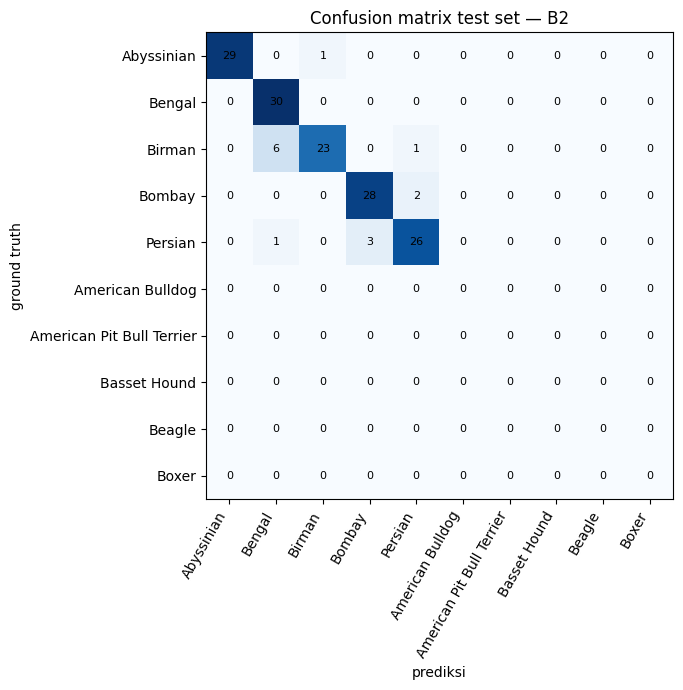

In [12]:
BEST_TAG = max(["B1", "B2", "B3"], key=lambda c: RESULTS[c]["val_acc_best"])
best = RESULTS[BEST_TAG]
print("Model terbaik (val acc):", BEST_TAG)

cm = confusion_matrix(best["ys"], best["preds"], labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(SELECTED, rotation=60, ha="right"); ax.set_yticklabels(SELECTED)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
ax.set_xlabel("prediksi"); ax.set_ylabel("ground truth"); ax.set_title(f"Confusion matrix test set — {BEST_TAG}")
plt.tight_layout()
plt.savefig(OUT / "figures" / f"confusion_{BEST_TAG}.png", dpi=150)
plt.show()

## 10. Failure analysis (C3): 8 misklasifikasi dengan confidence tertinggi

Jumlah misklasifikasi pada test set: 14 / 150


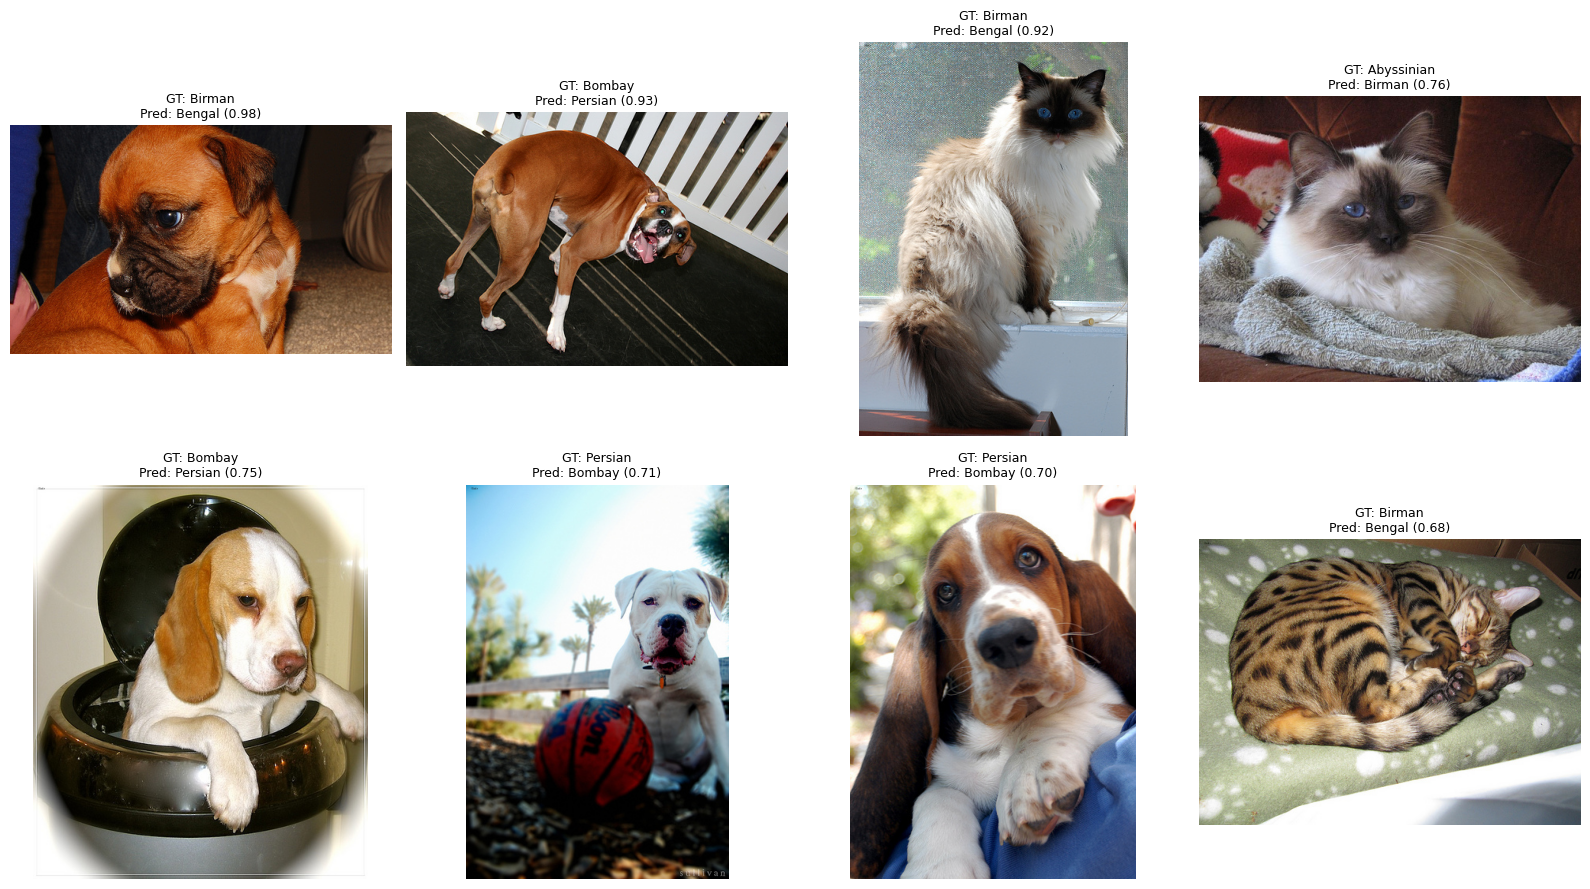

,test_sample_idx,ground_truth,prediksi,confidence_prediksi,prob_ground_truth,hipotesis_penyebab
0,17,Birman,Bengal,0.9812,0.0188,
1,133,Bombay,Persian,0.9255,0.0743,
2,58,Birman,Bengal,0.9200,0.0578,
3,73,Abyssinian,Birman,0.7623,0.2278,
4,102,Bombay,Persian,0.7492,0.2193,
5,8,Persian,Bombay,0.7060,0.2642,
6,103,Persian,Bombay,0.6969,0.3025,
7,113,Birman,Bengal,0.6784,0.3213,


In [13]:
def failure_analysis(res, k=8):
    wrong = np.where(res["preds"] != res["ys"])[0]
    print(f"Jumlah misklasifikasi pada test set: {len(wrong)} / {len(res['ys'])}")
    if len(wrong) == 0:
        return pd.DataFrame()
    conf = res["probs"][wrong, res["preds"][wrong]]
    order = wrong[np.argsort(-conf)][:k]

    fig, axes = plt.subplots(2, 4, figsize=(16, 9))
    rows = []
    for ax, j in zip(axes.flat, order):
        ax.imshow(IMAGES[SPLITS["test"][j]])
        ax.set_title(
            f"GT: {SELECTED[res['ys'][j]]}\n"
            f"Pred: {SELECTED[res['preds'][j]]} ({res['probs'][j, res['preds'][j]]:.2f})",
            fontsize=9,
        )
        ax.axis("off")
        rows.append({
            "test_sample_idx": int(j),
            "ground_truth": SELECTED[res["ys"][j]],
            "prediksi": SELECTED[res["preds"][j]],
            "confidence_prediksi": round(float(res["probs"][j, res["preds"][j]]), 4),
            "prob_ground_truth": round(float(res["probs"][j, res["ys"][j]]), 4),
            "hipotesis_penyebab": "",
        })
    for ax in axes.flat[len(order):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT / "figures" / f"failure_cases_{BEST_TAG}.png", dpi=150)
    plt.show()
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "metrics" / f"failure_cases_{BEST_TAG}.csv", index=False)
    return df


failure_df = failure_analysis(best)
failure_df

## 11. Grad-CAM pada layer4 sebelum dan sesudah fine-tuning (C5, opsional)
Membandingkan B2 (layer4 beku) dengan B3 (layer4 di-fine-tune) pada satu citra uji.

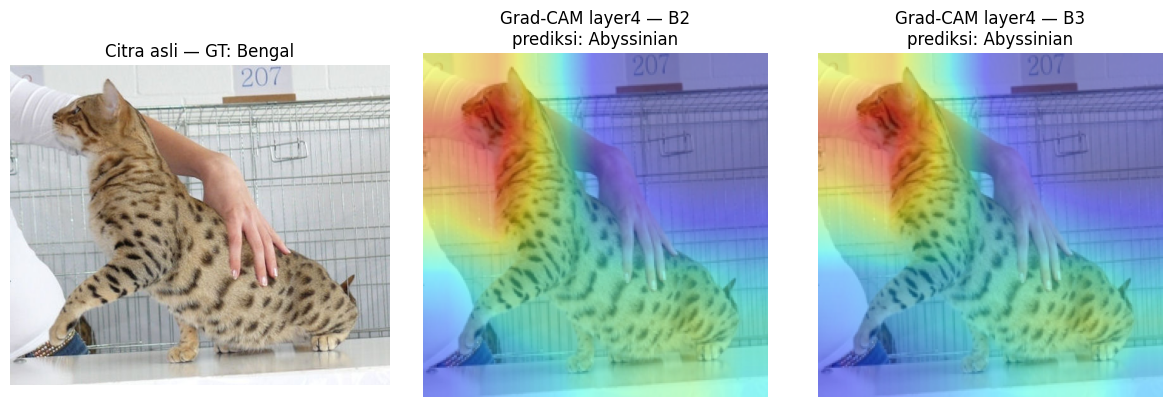

In [14]:
def grad_cam(model, x, target_layer, class_idx=None):
    acts, grads = {}, {}
    h1 = target_layer.register_forward_hook(lambda m, i, o: acts.__setitem__("v", o))
    h2 = target_layer.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("v", go[0]))
    model.eval()
    x = x.clone().requires_grad_(True)
    out = model(x)
    if class_idx is None:
        class_idx = int(out.argmax(1).item())
    model.zero_grad(set_to_none=True)
    out[0, class_idx].backward()
    h1.remove(); h2.remove()
    weights = grads["v"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * acts["v"]).sum(dim=1, keepdim=True))
    cam = nn.functional.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)
    cam = cam[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), class_idx


if "B2" in RESULTS and "B3" in RESULTS:
    sample_j = 0
    x_img, _ = PetSubset(IMAGES, LABELS, SPLITS["test"], TF_EVAL)[sample_j]
    x_img = x_img.unsqueeze(0).to(DEVICE)
    true_label = int(LABELS[SPLITS["test"][sample_j]])

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(IMAGES[SPLITS["test"][sample_j]]); axes[0].set_title(f"Citra asli — GT: {SELECTED[true_label]}")
    for ax, tag in zip(axes[1:], ["B2", "B3"]):
        cam, pred = grad_cam(RESULTS[tag]["model"], x_img, RESULTS[tag]["model"].layer4)
        ax.imshow(IMAGES[SPLITS["test"][sample_j]].resize((224, 224)))
        ax.imshow(cam, cmap="jet", alpha=0.45)
        ax.set_title(f"Grad-CAM layer4 — {tag}\nprediksi: {SELECTED[pred]}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT / "figures" / "gradcam_layer4_B2_vs_B3.png", dpi=150)
    plt.show()

## 12. Ringkasan akhir
Seluruh angka pada laporan harus berasal dari berkas di folder `outputs/metrics/`.

In [15]:
print("Berkas yang dihasilkan:")
for p in sorted((OUT).rglob("*")):
    if p.is_file():
        print(" ", p)

Berkas yang dihasilkan:
  outputs/figures/confusion_B2.png
  outputs/figures/failure_cases_B2.png
  outputs/figures/gradcam_layer4_B2_vs_B3.png
  outputs/figures/loss_curves_B1_B2_B3.png
  outputs/metrics/all_metrics.json
  outputs/metrics/failure_cases_B2.csv
  outputs/metrics/history_B1.csv
  outputs/metrics/history_B2.csv
  outputs/metrics/history_B3.csv
  outputs/metrics/history_B4_B2_noaug.csv
  outputs/metrics/history_B5_efficientnet_b0.csv
  outputs/metrics/history_B5_mobilenet_v3_small.csv
  outputs/metrics/metrics_B1.json
  outputs/metrics/metrics_B2.json
  outputs/metrics/metrics_B3.json
  outputs/metrics/metrics_B4_B2_noaug.json
  outputs/metrics/metrics_B5_efficientnet_b0.json
  outputs/metrics/metrics_B5_mobilenet_v3_small.json
  outputs/metrics/summary.csv


In [17]:
!ls -la outputs/metrics outputs/figures

outputs/figures:
total 4644
drwxr-xr-x 2 root root    4096 Oct 13 13:59 .
drwxr-xr-x 4 root root    4096 Oct 13 13:35 ..
-rw-r--r-- 1 root root   97140 Oct 13 13:58 confusion_B2.png
-rw-r--r-- 1 root root 3571981 Oct 13 13:58 failure_cases_B2.png
-rw-r--r-- 1 root root 1002269 Oct 13 13:59 gradcam_layer4_B2_vs_B3.png
-rw-r--r-- 1 root root   66132 Oct 13 13:51 loss_curves_B1_B2_B3.png

outputs/metrics:
total 68
drwxr-xr-x 2 root root 4096 Oct 13 13:58 .
drwxr-xr-x 4 root root 4096 Oct 13 13:35 ..
-rw-r--r-- 1 root root 2383 Oct 13 13:51 all_metrics.json
-rw-r--r-- 1 root root  359 Oct 13 13:58 failure_cases_B2.csv
-rw-r--r-- 1 root root 1453 Oct 13 13:39 history_B1.csv
-rw-r--r-- 1 root root 2785 Oct 13 13:43 history_B2.csv
-rw-r--r-- 1 root root  922 Oct 13 13:44 history_B3.csv
-rw-r--r-- 1 root root 2876 Oct 13 13:47 history_B4_B2_noaug.csv
-rw-r--r-- 1 root root 1627 Oct 13 13:49 history_B5_efficientnet_b0.csv
-rw-r--r-- 1 root root 1622 Oct 13 13:51 history_B5_mobilenet_v3_small.cs